# Introducción:

En este trabajo se utilizará una base de datos sintética extraída de [Kaggle](https://www.kaggle.com/), que contiene información sobre intentos de ciberataques. Con ella intentaremos conocer y analizar estos ataques, por ejemplo, como y donde se llevan a cabo, que particularidades tienen, que patrones existen, entre otras cosas. Y también observarlo desde al lugar de la víctima, sobre como reacciona o como le afecta. Para ello, se aplicarán medidas de resumen, tablas, gráficos, y entrenaremos algunos modelos de machine learning para predecir diferentes aspectos de estos ataques.

La ciberseguridad es un tema muy importante, delicado, el cual se debe conocer y enfatizar para evitar inconvenientes que pueden ser graves, y por ello es un tema intereseante de investigar. Aunque siempre teniendo claro que el objetivo principal es explorar, analizar datos, aplicar técnicas estadísticas.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Enterprise_Cyber_Kill_Chain_Dataset.csv")

# Datos:

Como se mencionó en la introducción, el dataset fue creado artificialmente de manera realista, sin ningún tipo de información personal.

Contiene toda la información de cada ataque, desde el primer momento en que se intenta hasta las consecuencias finales en la víctima.

Principal información del dataframe:

In [10]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())
print("Tipos de columnas\n", df.dtypes.value_counts().to_string())

Filas: 100500
Columnas: 50
Cantidad de ataques ('Incident_ID'): 100000
Tipos de columnas
 int64      25
str        14
float64    11


Eliminanos las filas duplicadas:

In [11]:
df = df.drop_duplicates()

print("Columnas:", df.shape[0])
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())


Columnas: 100000
Cantidad de ataques ('Incident_ID'): 100000


Entonces tenemos una base de datos con 100000 ataques diferentes y 50 variables que caracterizan cada uno de ellos. De estas 50, tenemos 25 númericas discretas, 11 continuas y 14 cualitativas. Debemos tener en cuenta que algunas de las 25 discretas, son binarias, que valen 1 si la observación cumple con esa variable, y 0 en caso contrario.

Las variables de respuesta o interés de este analisis son: `Attack_Success` que indica si el ataque tuvo éxito o no, y `Cyber_Risk_Score` que numera del 1 al 100 cada ataque según su nivel de riesgo.

<positron-console-cell-56>:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


Text(0, 0.5, 'Cantidad de ataques')

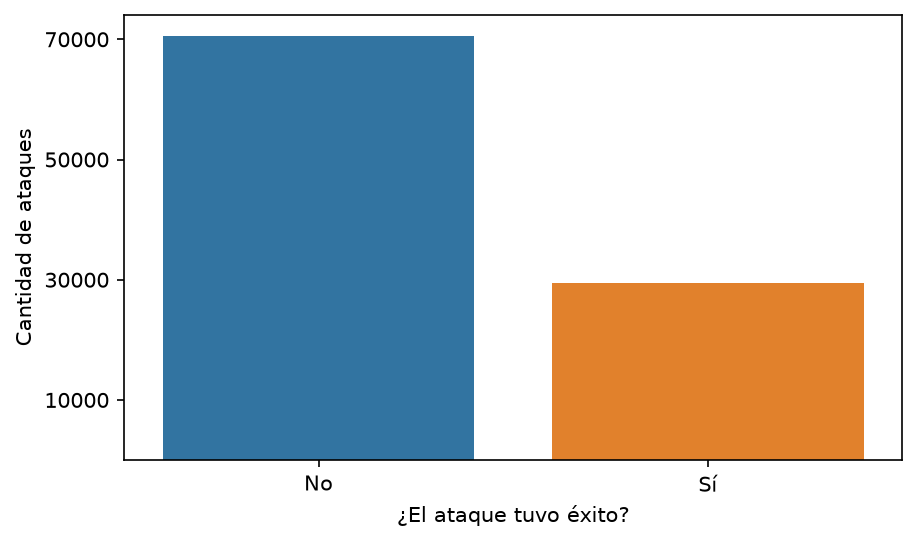

In [56]:
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
sns.countplot(data = df, x = "Attack_Success", hue = "Attack_Success", ax=ax)
ax.legend().remove()
ax.set_xticklabels(["No", "Sí"])
ax.set_yticks([10000,30000,50000,70000])
ax.set_xlabel("¿El ataque tuvo éxito?")
ax.set_ylabel("Cantidad de ataques")


Vemos que de todos los ataques, 70000, que equivale al 70%, fracasó y 30% restante efectivamente tuvo éxito. Estas cantidad exactas están claramente asociadas a la sintecidad de los datos. En datos reales, es muy poco probable que existan estos porcentajes enteros.

In [53]:
df["Cyber_Risk_Score"].describe(include = None)

count    100000.000000
mean         45.005120
std          19.047731
min           1.337935
25%          30.387444
50%          41.635008
75%          57.437351
max         100.000000
Name: Cyber_Risk_Score, dtype: float64

Text(0, 0.5, 'Cantidad')

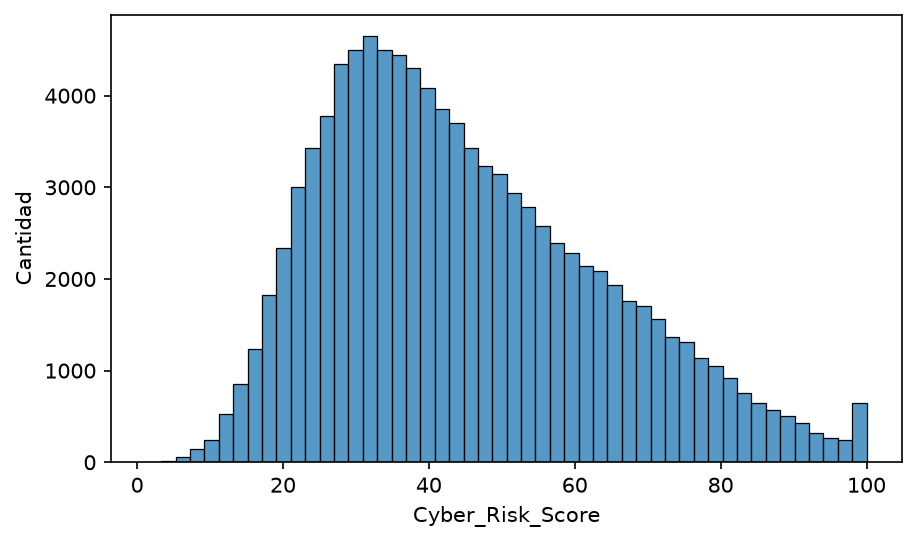

In [61]:
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
sns.histplot(data=df, x="Cyber_Risk_Score", ax=ax, fill = True, bins = 50)
ax.set_ylabel("Cantidad")


EL nivel de riesgo del ataque observamos que tiene una distribución, con media 45 y asimetría a la derecha, donde el tercer percentil es 57.4 y el máximo 100. Destacando el último intevalo que rompe con el patrón, y tiene bastante observaciones relativamente.